# 04 · Replication: CDK2 (R2) and immune-associated expression (R3)

**What this notebook does.** It maps selected genes on the tissue for every usable section and puts them next to
the exact published numbers they relate to. It does **not** compare nevus and melanoma regions, because the paper's
region labels (which spots are nevus or melanoma) are not public.

**What the paper did (for context).** The authors split each spot's expression into 15 profiles with a statistical
method (STdeconvolve), named the profiles by comparing them with published cell-type signatures, and labelled every
spot with its most abundant profile ("Nevus", "Melanoma 1", "Melanoma 2", "Immune cells 1", ...). Their CDK2 result
compares spots labelled Melanoma 1 with spots labelled Nevus (Supplementary Table S4, S5). Their immune results come
from those profiles, from a reference-based estimate of immune cell fractions (Fig. 5C, Supp. Fig. S9D), and from
imaging mass cytometry protein stains (Fig. 5B/D, Supp. Table S3).

**What changed compared with the old notebook.**
* The violin plot "CDK2 by sample-level pathology" is **removed**: it coloured whole capture areas as "melanoma"
  from the GEO title wording, so it was not a nevus-vs-melanoma comparison of any kind.
* Normalisation is done on a **copy** (`lognormalised_copy`); raw counts are never overwritten.
* The "macrophage score" = mean(CD163, PTPRC) is **removed**. PTPRC (CD45) is expressed by all white blood cells,
  so the average is not macrophage-specific. It is replaced by single-marker maps and clearly labelled provisional
  gene scores (section 4.6).
* Only QC-passing spots (notebook 02) are used.

| | |
|---|---|
| **Inputs** | processed `.h5ad` files with QC, Supplementary Tables S4/S5 |
| **Outputs** | `figures/04_replication/*.png`, `manifests/r2_published_reference.csv`, `manifests/r2_detection_by_section.csv`, `manifests/r3_marker_presence.csv`, `manifests/r3_evidence_levels.csv` |

In [1]:
# --- Setup: make src/ importable, load helpers, define all paths -------------
import sys
from pathlib import Path
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacemel_io as sio        # all data processing
import spacemel_plots as splot   # all drawing

P = sio.get_paths()
sio.ensure_output_dirs(P)
FIG = P["figures"] / "04_replication"
FIG.mkdir(parents=True, exist_ok=True)
MAN = P["manifests"]
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
print("repo      :", P["repo"])
print("raw data  :", P["raw"])
print("figures ->:", FIG)
print("manifests:", MAN)

repo      : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval
raw data  : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw
figures ->: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\04_replication
manifests: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests


## 4.1 · Load QC-passing spots and normalise (on a copy)

Normalisation used here: counts per spot scaled to 10,000 and log-transformed, `log(1 + x)`. This corrects for the
different amount of RNA captured per spot. The authors used Seurat SCTransform instead (their scripts use the
`SCT` assay), so absolute values are not comparable with the paper; detection (count > 0) is.

In [2]:
usable = sio.usable_sections(P)
qc_summary = pd.read_csv(MAN / "qc_summary.csv")
order = [s for s in qc_summary.section_id if any(s == ss for _, ss in usable)]
gsm_of = {s: g for g, s in usable}
data = {}
for s in order:
    a = sio.read_processed(P, gsm_of[s], s)
    a = a[a.obs.qc_pass.to_numpy()].copy()
    data[s] = sio.lognormalised_copy(a)
pd.Series({s: b.n_obs for s, b in data.items()}, name="qc_pass_spots").to_frame().T

,D20,B1,B38ex,A24,A21,A22,D3,B4,A23,A16,B38_2,B13,A34,A7,A17,B15,B14,B8
qc_pass_spots,1056,3931,1855,6059,1934,4081,1208,5419,2143,2768,1094,1536,1631,1289,863,1069,669,878


## 4.2 · Published reference values (R2)

Read directly from the paper's supplementary tables.
* **Table S4** (differential expression, Melanoma-1-labelled vs Nevus-labelled spots): `avg_log2FC` and the fraction
  of spots of each label in which the gene is detected.
* **Table S5** ("on/off" genes): percentage of spots with expression, for all labelled spots and for spots whose
  estimated purity is ≥ 75 %; `#... ≥50% spots` = number of individuals in which > 50 % of that label's spots express it.

HHATL and SNX10 are the genes shown spatially in **Fig. 2D** (HHATL blue, SNX10 yellow, rescaled 0–1).
PRAME is the immunohistochemistry marker used for melanoma in Fig. 1E.

In [3]:
assert P["supp_tables"].exists(), f"Supplementary tables not found: {P['supp_tables'].name} - see README, Input data"
R2_GENES = ["CDK2", "PRAME", "SNX10", "HHATL"]
s4 = sio.load_supp_table(P["supp_tables"], "S4")
s5 = sio.load_supp_table(P["supp_tables"], "S5")
ref = (s4[s4.Gene.isin(R2_GENES)][["Gene", "avg_log2FC", "fractions of melanoma 1 spots", "fractions of nevus spots", "p_val_adj"]]
       .merge(s5[s5.Gene.isin(R2_GENES)], on="Gene", how="left", suffixes=("_S4", "_S5")))
ref.to_csv(MAN / "r2_published_reference.csv", index=False)
ref.T

,0,1,2,3
Gene,CDK2,PRAME,SNX10,HHATL
avg_log2FC,3.864463,2.734734,2.169803,-8.59788
fractions of melanoma 1 spots,0.928,0.958,0.954,0.01
fractions of nevus spots,0.2,0.251,0.303,0.596
p_val_adj,0.0,0.0,0.0,0.0
Melanoma 1 (%),84.35226,90.90247,91.9214,1.965066
#Melanoma 1 ≥50% spots,7,8,10,0
Melanoma 1 (%) (≥75% purity),99.81651,100.0,98.34862,0.122324
Nevus (%),24.93274,31.03139,35.96413,51.30045
#Nevus ≥50% spots,0,2,2,9


## 4.3 · CDK2 on the tissue, every section

Two views per section, both at true spot size on the hires H&E:
* **detection map**: spot is coloured if at least one CDK2 count was observed (this is the quantity in Tables S4/S5);
* **expression map**: log-normalised CDK2, rescaled 0–1 per section with the top 1 % capped (the authors' plotting
  call used `scale = "free", max_cutoff = 0.99`). Colours are therefore **not comparable between sections**.

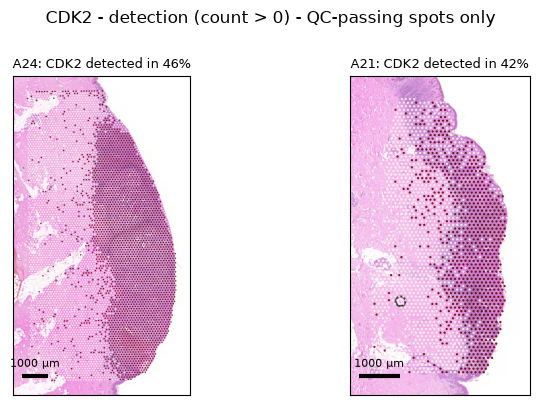

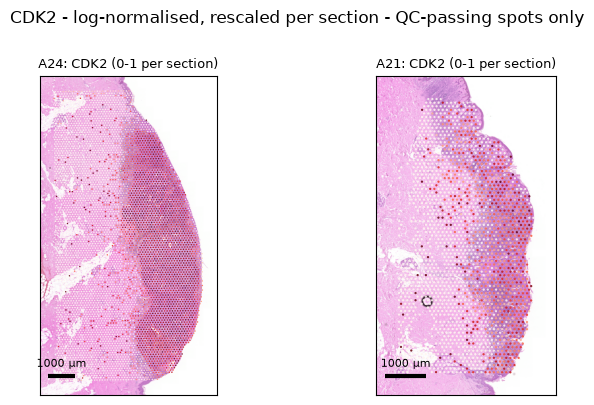

In [4]:
SHOW = ["A24", "A21"]   # example sections shown in the notebook; all sections are saved to figures/04_replication/

def gene_grid(gene, mode, cmap, fname, sections=None, show=False):
    """Draw one gene on the H&E for the given sections. Saved only when fname is given; displayed only if show=True."""
    sections = sections or order
    fig, axes = splot.grid_axes(len(sections), ncols=min(4, len(sections)), size=4.0)
    for ax, s in zip(np.atleast_1d(axes), sections):
        b = data[s]
        if gene not in b.var_names:
            ax.set_title(f"{s}: {gene} not in panel", fontsize=9); ax.axis("off"); continue
        img, x, y, um = sio.section_image(P, b, "hires")
        if mode == "detect":
            v = (sio.gene_vector(b, gene, layer="counts") > 0).astype(float)
            title = f"{s}: {gene} detected in {v.mean():.0%}"
        else:
            v = sio.rescale_free(sio.gene_vector(b, gene))
            title = f"{s}: {gene} (0-1 per section)"
        splot.section_map(ax, img, x, y, sio.SPOT_DIAMETER_UM / um, um, values=v, cmap=cmap,
                          vmin=0, vmax=1, title=title, alpha=0.85)
    fig.suptitle(f"{gene} - {'detection (count > 0)' if mode == 'detect' else 'log-normalised, rescaled per section'}"
                 " - QC-passing spots only", y=1.0)
    fig.tight_layout()
    if fname:
        splot.savefig(fig, FIG / fname)
    if show:
        plt.show()
    plt.close(fig)

def gene_maps(gene, mode, cmap, fname):
    """All sections -> saved file; example sections -> shown here and saved."""
    gene_grid(gene, mode, cmap, fname)
    gene_grid(gene, mode, cmap, fname.replace("all_sections", "examples_" + "_".join(SHOW)), sections=SHOW, show=True)

gene_maps("CDK2", "detect", "Reds", "R2_CDK2_detection_all_sections.png")
gene_maps("CDK2", "expr", "Reds", "R2_CDK2_expression_all_sections.png")

Two sections are shown here as examples (`SHOW` = A24, A21); the maps for all 18 sections are saved in
`figures/04_replication/` (`*_all_sections.png`). The example figures are also saved as `*_examples_A24_A21.png`.

## 4.4 · Fig. 2D-style maps (HHATL blue, SNX10 yellow) and PRAME

Same layout as the published Fig. 2D: HHATL in blue and SNX10 in yellow, each rescaled 0–1 per section; a spot's
opacity is the larger of the two values. In the paper HHATL is detected mainly in nevus-labelled spots and SNX10 in
melanoma-labelled spots (4.2). The maps below only show **where** each gene is expressed; they do not label regions.

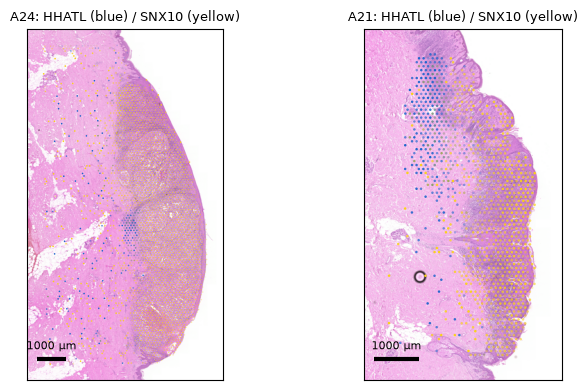

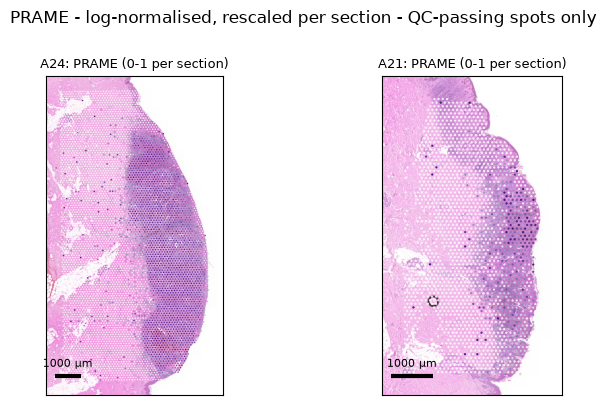

In [5]:
BLUE, YELLOW = np.array([0.13, 0.40, 0.80]), np.array([0.98, 0.82, 0.10])

def fig2d_grid(sections, fname=None, show=False):
    fig, axes = splot.grid_axes(len(sections), ncols=min(4, len(sections)), size=4.0)
    for ax, s in zip(np.atleast_1d(axes), sections):
        b = data[s]
        if not {"HHATL", "SNX10"} <= set(b.var_names):
            ax.set_title(f"{s}: gene missing from panel", fontsize=9); ax.axis("off"); continue
        img, x, y, um = sio.section_image(P, b, "hires")
        h = sio.rescale_free(sio.gene_vector(b, "HHATL"))
        y_ = sio.rescale_free(sio.gene_vector(b, "SNX10"))
        tot = h + y_
        w_h = np.divide(h, tot, out=np.zeros_like(h), where=tot > 0)
        rgba = np.column_stack([w_h[:, None] * BLUE + (1 - w_h[:, None]) * YELLOW, np.maximum(h, y_)])
        splot.section_map(ax, img, x, y, sio.SPOT_DIAMETER_UM / um, um, facecolors=rgba, alpha=None,
                          title=f"{s}: HHATL (blue) / SNX10 (yellow)")
    fig.tight_layout()
    if fname:
        splot.savefig(fig, FIG / fname)
    if show:
        plt.show()
    plt.close(fig)

fig2d_grid(order, fname="R2_HHATL_SNX10_fig2D_style_all_sections.png")
fig2d_grid(SHOW, fname=f"R2_HHATL_SNX10_fig2D_style_examples_{'_'.join(SHOW)}.png", show=True)

gene_maps("PRAME", "expr", "Purples", "R2_PRAME_expression_all_sections.png")

## 4.5 · Detection rates and co-expression per section

For each section (QC-passing spots): percentage of spots in which each gene is detected, and how often CDK2 is
detected in spots where PRAME is / is not detected, plus Spearman correlations between log-normalised genes.

**Caution.** "PRAME detected" is an RNA-defined grouping, not a pathology label. These numbers describe co-occurrence
of transcripts within spots; they are not a nevus-vs-melanoma comparison and must not be reported as one.
The published values for comparison are in 4.2.

In [6]:
from scipy.stats import spearmanr
rows = []
for s in order:
    b = data[s]
    r = {"section_id": s, "gsm": gsm_of[s], "n_spots": b.n_obs}
    present = [gname for gname in R2_GENES if gname in b.var_names]
    det = {gname: sio.gene_vector(b, gname, layer="counts") > 0 for gname in present}
    for gname in present:
        r[f"pct_{gname}_detected"] = round(100 * det[gname].mean(), 1)
    if {"CDK2", "PRAME"} <= set(present):
        p = det["PRAME"]
        r["pct_CDK2_in_PRAME_detected"] = round(100 * det["CDK2"][p].mean(), 1) if p.any() else np.nan
        r["pct_CDK2_in_PRAME_not_detected"] = round(100 * det["CDK2"][~p].mean(), 1) if (~p).any() else np.nan
        for other in ["PRAME", "SNX10", "HHATL"]:
            if other in present:
                r[f"spearman_CDK2_{other}"] = round(spearmanr(sio.gene_vector(b, "CDK2"),
                                                              sio.gene_vector(b, other)).statistic, 3)
    rows.append(r)
r2_table = pd.DataFrame(rows)
r2_table.to_csv(MAN / "r2_detection_by_section.csv", index=False)
r2_table

,section_id,gsm,n_spots,pct_CDK2_detected,pct_PRAME_detected,pct_SNX10_detected,pct_HHATL_detected,pct_CDK2_in_PRAME_detected,pct_CDK2_in_PRAME_not_detected,spearman_CDK2_PRAME,spearman_CDK2_SNX10,spearman_CDK2_HHATL
0,D20,GSM9022973,1056,46.8,43.7,51.2,26.8,83.9,18.0,0.638,0.574,-0.197
1,B1,GSM9022969,3931,39.9,30.0,46.9,35.3,82.3,21.7,0.575,0.451,0.065
2,B38ex,GSM9022969,1855,29.0,14.2,28.1,4.6,85.2,19.7,0.539,0.469,0.121
3,A24,GSM9022967,6059,46.2,43.7,47.5,7.1,92.1,10.5,0.843,0.706,0.081
4,A21,GSM9022965,1934,42.3,25.9,46.6,19.0,86.0,27.0,0.468,0.454,-0.149
5,A22,GSM9022967,4081,23.1,20.0,23.4,8.3,62.3,13.3,0.399,0.368,0.103
6,D3,GSM9022973,1208,23.6,11.6,18.4,12.7,67.9,17.8,0.347,0.349,0.346
7,B4,GSM9022970,5419,24.7,15.0,23.7,15.7,89.7,13.3,0.655,0.632,0.294
8,A23,GSM9022966,2143,25.5,23.0,18.3,9.7,69.9,12.3,0.498,0.336,0.145
9,A16,GSM9022966,2768,36.3,40.2,38.5,14.4,78.7,7.8,0.672,0.621,0.152


## 4.6 · Immune-associated expression (R3)

### Markers and what they indicate

| Gene | Protein | Usually expressed by | Why it is here |
|---|---|---|---|
| PTPRC | CD45 | all white blood cells (leukocytes) | general immune presence |
| CD3D, CD3E | CD3 complex | T cells | T-cell presence |
| CD8A | CD8 | cytotoxic T cells | T-cell subset |
| FOXP3 | FOXP3 | regulatory T cells | listed as the Treg marker in the paper's IMC panel (Supp. Table S3) |
| CD14, CD68, CD163 | CD14, CD68, CD163 | macrophages / monocytes | the paper's IMC definition of macrophages is CD14+CD68+CD163+ (Supp. Table S3) |

A Visium spot is 55 µm wide and contains several cells (the paper states 5–10, Methods), so a marker signal in a spot
means *the transcript was present in the mixture of cells under that spot*, not that a specific cell type is
confirmed there.

In [7]:
IMMUNE = ["PTPRC", "CD3D", "CD3E", "CD8A", "FOXP3", "CD14", "CD68", "CD163"]
presence = pd.DataFrame({s: {gname: gname in data[s].var_names for gname in IMMUNE} for s in order}).T
presence.to_csv(MAN / "r3_marker_presence.csv")
presence

,PTPRC,CD3D,CD3E,CD8A,FOXP3,CD14,CD68,CD163
D20,True,True,True,True,True,True,True,True
B1,True,True,True,True,True,True,True,True
B38ex,True,True,True,True,True,True,True,True
A24,True,True,True,True,True,True,True,True
A21,True,True,True,True,True,True,True,True
A22,True,True,True,True,True,True,True,True
D3,True,True,True,True,True,True,True,True
B4,True,True,True,True,True,True,True,True
A23,True,True,True,True,True,True,True,True
A16,True,True,True,True,True,True,True,True


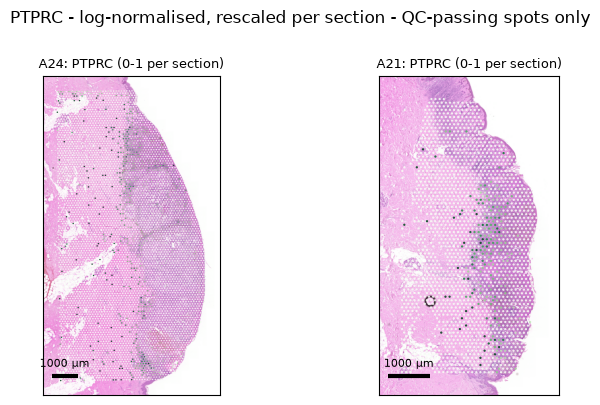

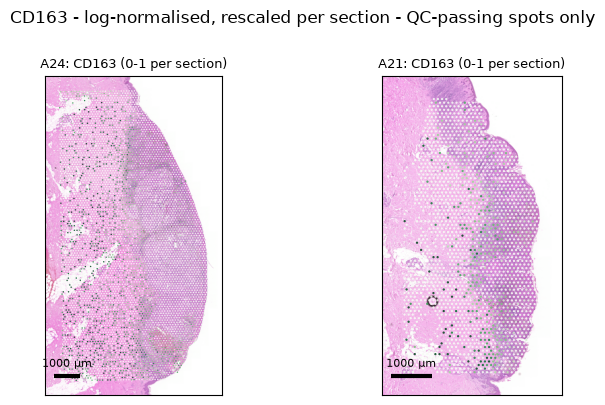

In [8]:
SHOW_MARKERS = ["PTPRC", "CD163"]
for gname in IMMUNE:
    gene_grid(gname, "expr", "Greens", f"R3_{gname}_expression_all_sections.png")
    if gname in SHOW_MARKERS:
        gene_grid(gname, "expr", "Greens", f"R3_{gname}_expression_examples_{'_'.join(SHOW)}.png", sections=SHOW, show=True)

### Provisional gene scores

Two scores, computed per section with `scanpy.tl.score_genes`: mean log-normalised expression of the listed genes
minus the mean of randomly drawn control genes with similar average expression (`random_state = 0`).
* `Tcell_assoc_score_provisional`: CD3D, CD3E (pan-T-cell genes; CD8A is shown separately above).
* `macrophage_assoc_score_provisional`: CD14, CD68, CD163 (RNA counterparts of the paper's IMC macrophage proteins).

These scores have **not** been validated against cell counts or protein stains in this dataset. Because control genes
are drawn per section, values are not comparable between sections.

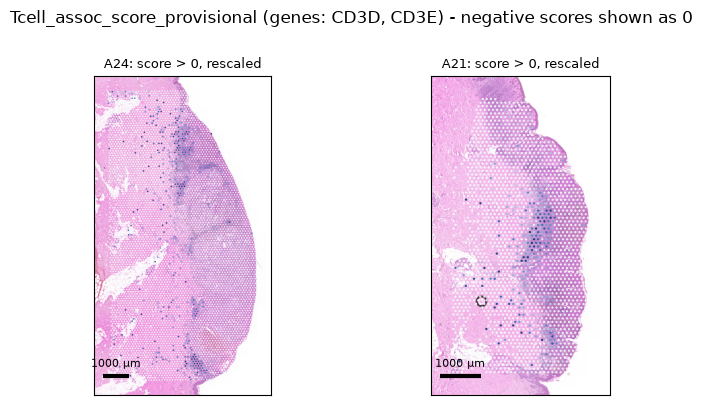

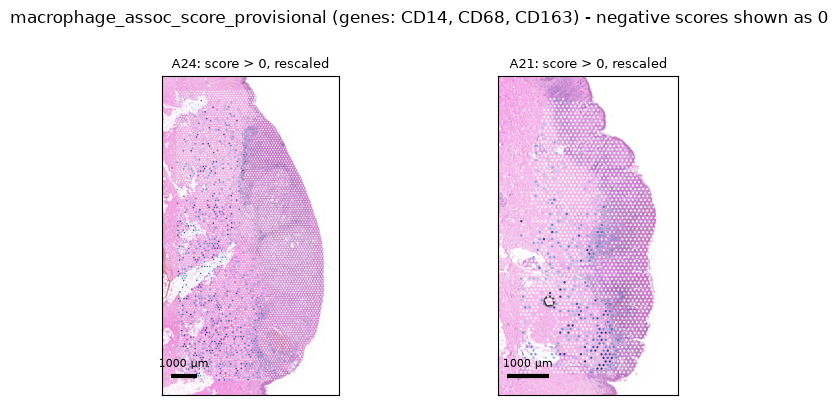

In [9]:
import scanpy as sc

SCORES = {"Tcell_assoc_score_provisional": ["CD3D", "CD3E"],
          "macrophage_assoc_score_provisional": ["CD14", "CD68", "CD163"]}

# 1) compute the scores per section
for s in order:
    b = data[s]
    for name, genes in SCORES.items():
        genes = [x for x in genes if x in b.var_names]
        if genes:
            sc.tl.score_genes(b, genes, score_name=name, random_state=0)
        else:
            b.obs[name] = np.nan
            print(f"{s}: no genes of {name} in panel")

# 2) draw: all sections saved, example sections (SHOW) displayed
def score_grid(name, sections, fname=None, show=False):
    fig, axes = splot.grid_axes(len(sections), ncols=min(4, len(sections)), size=4.0)
    for ax, s in zip(np.atleast_1d(axes), sections):
        b = data[s]
        img, x, y, um = sio.section_image(P, b, "hires")
        v = sio.rescale_free(np.nan_to_num(np.clip(b.obs[name].to_numpy(), 0, None)))
        splot.section_map(ax, img, x, y, sio.SPOT_DIAMETER_UM / um, um, values=v, cmap="Blues",
                          vmin=0, vmax=1, title=f"{s}: score > 0, rescaled", alpha=0.85)
    fig.suptitle(f"{name} (genes: {', '.join(SCORES[name])}) - negative scores shown as 0", y=1.0)
    fig.tight_layout()
    if fname:
        splot.savefig(fig, FIG / fname)
    if show:
        plt.show()
    plt.close(fig)

for name in SCORES:
    score_grid(name, order, fname=f"R3_{name}_all_sections.png")
    score_grid(name, SHOW, fname=f"R3_{name}_examples_{'_'.join(SHOW)}.png", show=True)

In the notebook, PTPRC and CD163 are shown for the two example sections; maps of all eight markers and both scores for
all sections are saved in `figures/04_replication/`.

### Evidence level of every immune output

Every immune-related output must state what kind of evidence it is. Levels used in this project:
1. **single marker RNA**: one gene's transcripts in a spot;
2. **provisional gene score**: combination of a few genes, not validated here;
3. **inferred cell composition**: cell fractions estimated with a reference or deconvolution (not done here);
4. **independently validated cell identity**: e.g. protein staining (IMC) on the same tissue (not available here; the
   paper's IMC data are on Zenodo, doi:10.5281/zenodo.15582615, on adjacent sections of 9 lesions).

In [10]:
levels = pd.DataFrame([
    {"output": f"{g} expression map", "evidence_level": "1 - single marker RNA", "validated_here": False} for g in IMMUNE
] + [
    {"output": n, "evidence_level": "2 - provisional gene score", "validated_here": False} for n in SCORES
] + [
    {"output": "paper Fig. 5A/5C, Supp. Fig. S9D (immune profiles, estimated fractions)",
     "evidence_level": "3 - inferred cell composition (authors)", "validated_here": False},
    {"output": "paper Fig. 5B/5D, Supp. Fig. S9B/C (IMC)",
     "evidence_level": "4 - protein-level cell identity (authors, adjacent section)", "validated_here": False},
])
levels.to_csv(MAN / "r3_evidence_levels.csv", index=False)
levels

,output,evidence_level,validated_here
0,PTPRC expression map,1 - single marker RNA,False
1,CD3D expression map,1 - single marker RNA,False
2,CD3E expression map,1 - single marker RNA,False
3,CD8A expression map,1 - single marker RNA,False
4,FOXP3 expression map,1 - single marker RNA,False
5,CD14 expression map,1 - single marker RNA,False
6,CD68 expression map,1 - single marker RNA,False
7,CD163 expression map,1 - single marker RNA,False
8,Tcell_assoc_score_provisional,2 - provisional gene score,False
9,macrophage_assoc_score_provisional,2 - provisional gene score,False


## 4.7 · Replication record

| Target | Published result (exact reference) | Our output | Agrees | Differs | Cannot be verified | Exact / approximate / not reproduced |
|---|---|---|---|---|---|---|
| R2 CDK2 | Table S4: CDK2 higher in Melanoma-1-labelled than nevus-labelled spots (avg_log2FC 3.86; detected in 92.8 % vs 20.0 % of spots); Table S5: 99.8 % vs 10.7 % (≥ 75 % purity) | 4.3, 4.5 | Direction is consistent at the level of RNA co-occurrence: in 17 of 18 sections CDK2 is detected more often in spots where PRAME (a melanoma marker) is detected than where it is not;   CDK2 correlates positively with PRAME in 17 of 18 sections (Spearman up to 0.84; A7 −0.02) and with SNX10 in all 18 (0.16 to 0.71) | Our detection rates (11.5–46.8 % of QC-passing spots) refer to all spots, not to labelled nevus/melanoma spots, and depend on sequencing depth, so they are not comparable with the published percentages | The nevus-vs-melanoma comparison itself: the authors' spot labels are not public | Not reproduced (only an RNA-defined approximation) |
| R2 Fig. 2D | HHATL (nevus) / SNX10 (melanoma) spatial maps | 4.4 | In several sections HHATL and SNX10 are high in separate, adjacent areas (e.g. D20, A21, B1, B4, A7) | Published map shows one unnamed lesion; colours rescaled differently | Which section Fig. 2D shows | Approximate (qualitative) |
| R3 immune | Fig. 5A–D, Supp. Fig. S9: more immune cells around melanoma than nevus; CD163+ macrophages within the nevus (IMC protein) | 4.6 | Immune-marker RNA is present in all sections; T-cell-associated signal forms bands in some sections (e.g. B1, A21, B4, A24) | Our outputs are single-marker RNA and provisional scores (evidence levels 1–2); the paper's are inferred composition and protein (levels 3–4) | Location relative to nevus/melanoma regions (labels not public); cell identity | Not reproduced (only RNA-level description) |

## 4.8 · Observations

*From the outputs of this run (8 Nov 2026).*

* **Spots used (4.1).** 669 (B14) to 6,059 (A24) QC-passing spots per section.
* **Published values (4.2).** Read from Tables S4/S5: CDK2 avg_log2FC 3.86, detected in 92.8 % of Melanoma-1 and
  20.0 % of nevus spots (S4); 84.4 % vs 24.9 % of all labelled spots and 99.8 % vs 10.7 % at ≥ 75 % purity (S5).
  The two tables give different percentages for all labelled spots; the paper does not explain the difference.
* **CDK2 on tissue (4.3).** CDK2 is detected in 11.5 % (A34) to 46.8 % (D20) of QC-passing spots. The highest rates are
  in the sections with the highest sequencing depth (D20, A24, B1; notebook 02), so detection rates are not
  comparable between sections without accounting for depth. Within sections, CDK2-detected spots are concentrated in
  the densely stained areas of the tissue (e.g. A24, B1, B4, A21).
* **Fig. 2D-style maps (4.4).** In several sections HHATL and SNX10 are high in separate, adjacent areas
  (e.g. D20, A21, B1, B4, A7); in others one of the two is nearly absent.
* **Co-occurrence (4.5).** In 17 of 18 sections CDK2 is detected more often in PRAME-detected spots (21–92 %) than in
  PRAME-negative spots (8–28 %); the exception is A7, where PRAME is detected in only 1.5 % of spots. Spearman
  correlation of CDK2 with PRAME: −0.02 to 0.84; with SNX10: 0.16 to 0.71; with HHATL: −0.20 to 0.35.
  These are RNA-defined groupings, not nevus/melanoma comparisons.
* **Immune markers (4.6).** All eight markers are present in both gene panels for all 18 sections. The provisional
  T-cell-associated score is highest in band-like areas in some sections (e.g. B1, A21, B4, A24). All immune outputs
  here are evidence level 1 (single marker) or 2 (provisional score); none is validated as cell identity.
* In A24 and A21 the provisional macrophage-associated score (CD14, CD68, CD163) is positive mainly in the
  lighter-stained tissue next to the densely stained area and mostly ≤ 0 within it.